# AI4I — 결과에서 출발해 원인을 찾고, 데이터를 다듬어 다시 학습하기

정답 규칙을 미리 알고 넣지 않고, **분석으로 찾아낸 것만** 파생 변수 · 정제에 씁니다.

| 단계 | 하는 일 | 쓰는 데이터 |
|---|---|---|
| 0 | 기준 결과 — 어느 클래스가 문제인가 | train으로 학습 · val로 확인 |
| 1 | 틀린 행 살펴보기 | train(교차 검증 예측) |
| 2 | 영향 변수 찾기 — permutation importance | train |
| 3 | 그림으로 경계 모양 보기 | train |
| 3-1 | 분포 이동 확인 — 몫 사이에 흘러가는 변수 | train · val |
| 4 | 변수 조합 자동 탐색 — 곱 · 비 · 차 | train |
| 5 | 구간 찾기 — 얕은 결정 트리 | train |
| 6 | 정답 잡음 확인 | train |
| 7 | 정제안 비교 → 고르기 | train 학습 · **val로 고름** |
| 8 | 전후 비교 | **test는 여기서 한 번만** |

- 빠르게 여러 번 돌리려고 분석 · 비교는 scikit-learn `HistGradientBoostingClassifier`(같은 설정)로 합니다. 마지막에 AutoGluon으로 다시 확인하는 칸이 있습니다.
- 실행: 같은 폴더 `requirements.txt` 설치 뒤, 이 노트북을 `examples/` 폴더에서 엽니다.

## 준비

In [6]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report, f1_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
KFONT = next((f for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"] if f in _have), "sans-serif")
sns.set_theme(style="whitegrid", font=KFONT)   # 그림 속 한글
plt.rcParams["axes.unicode_minus"] = False

DATA = Path("../csv")
assert (DATA / "ai4i-train.csv").exists(), "DATA 경로를 csv 폴더로 맞춰 주세요"
SEED = 20261022
CLASSES = ["NONE", "TWF", "HDF", "PWF", "OSF"]
FAILS = ["TWF", "HDF", "PWF", "OSF"]
RAW = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
SHORT = {"Air temperature [K]": "air", "Process temperature [K]": "proc", "Rotational speed [rpm]": "rpm",
         "Torque [Nm]": "torque", "Tool wear [min]": "wear"}


def load(name):
    df = pd.read_csv(DATA / f"ai4i-{name}.csv").rename(columns=SHORT)
    df["label"] = "NONE"
    for t in ["OSF", "PWF", "HDF", "TWF"]:          # 유형이 둘 이상인 행은 TWF > HDF > PWF > OSF 하나로(6단계에서 다시 봄)
        df.loc[df[t] == 1, "label"] = t
    df["type_code"] = df["Type"].map({"L": 0, "M": 1, "H": 2})
    return df


train, val, test = load("train"), load("val"), load("test")
BASE = ["type_code", "air", "proc", "rpm", "torque", "wear"]
NUM = ["air", "proc", "rpm", "torque", "wear"]
train["label"].value_counts()

label
NONE    5561
PWF       53
HDF       49
OSF       46
TWF       26
Name: count, dtype: int64

In [7]:
def model():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced",
                                          categorical_features=[0], random_state=SEED)   # 0번 칸 = type_code


def fit_eval(tr, ev, feats, title=None, show=True):
    m = model().fit(tr[feats], tr["label"])
    pred = m.predict(ev[feats])
    rep = classification_report(ev["label"], pred, labels=CLASSES, output_dict=True, zero_division=0)
    f1 = {c: rep[c]["f1-score"] for c in CLASSES}
    f1["macro"] = f1_score(ev["label"], pred, labels=CLASSES, average="macro", zero_division=0)
    if show:
        fig, ax = plt.subplots(figsize=(4.6, 4))
        ConfusionMatrixDisplay.from_predictions(ev["label"], pred, labels=CLASSES, ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(title or "")
        plt.show()
    return m, f1

## 0. 기준 결과 — 원래 칸 6개, val로 확인

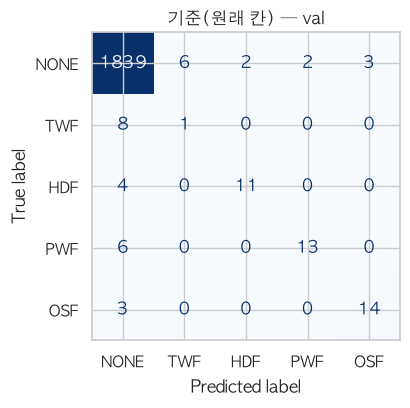

,f1 (val)
NONE,0.991
TWF,0.125
HDF,0.786
PWF,0.765
OSF,0.824
macro,0.698


In [8]:
base_model, base_val = fit_eval(train, val, BASE, "기준(원래 칸) — val")
pd.Series(base_val).round(3).to_frame("f1 (val)")

**읽을 점:** 어느 클래스의 f1이 낮은지 봅니다(앞선 AutoGluon 결과에서는 TWF · OSF가 낮았음). 아래 분석은 그 두 클래스의 원인을 찾는 데 집중합니다.

## 1. 틀린 행 살펴보기 — train 교차 검증 예측(val · test는 보지 않음)

예측    HDF  NONE  OSF  PWF  TWF
정답                            
HDF    43     5    0    1    0
NONE    3  5526    7   15   10
OSF     0     8   38    0    0
PWF     1    14    2   36    0
TWF     0    25    0    1    0


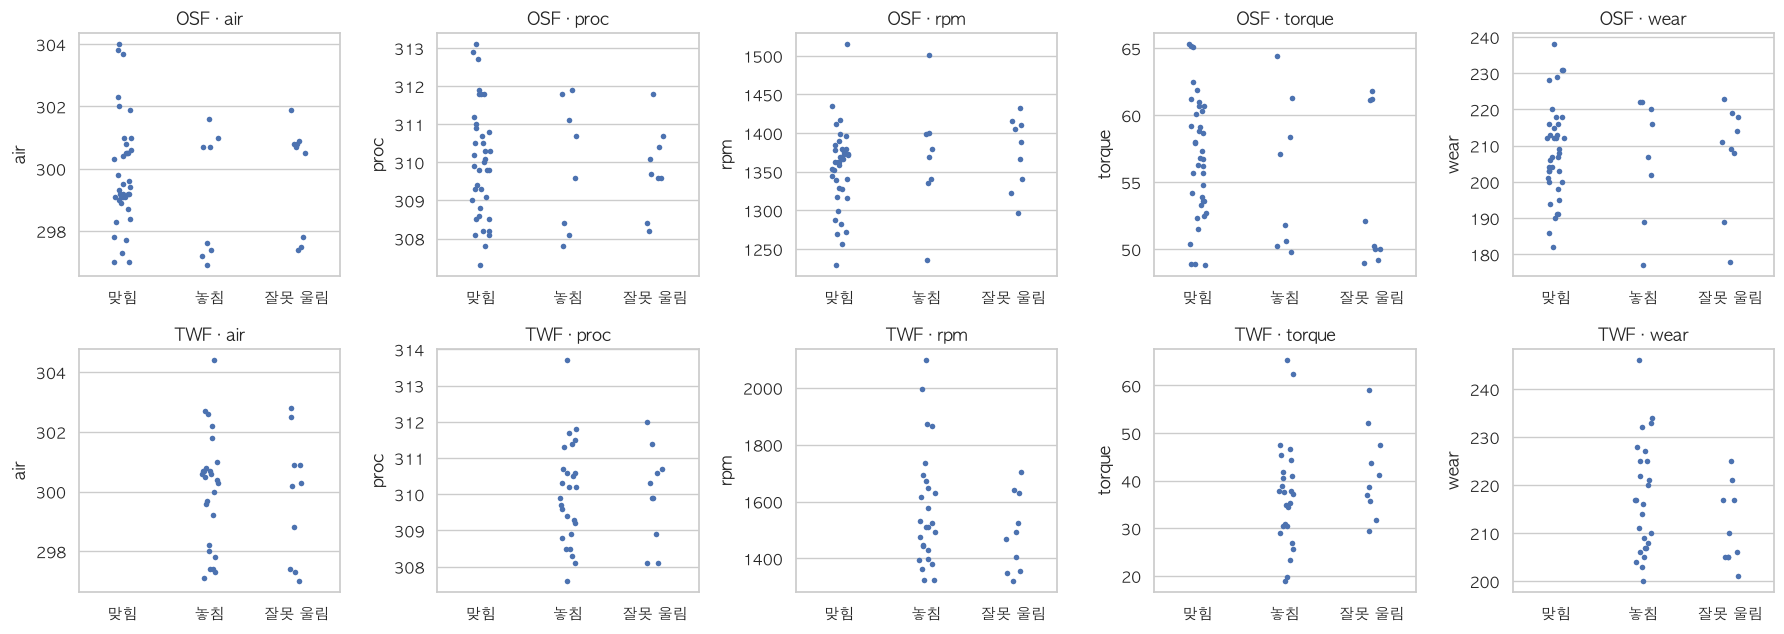

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
train["cv_pred"] = cross_val_predict(model(), train[BASE], train["label"], cv=cv)
train["result"] = np.where(train["label"] == train["cv_pred"], "맞힘", "틀림")
print(pd.crosstab(train["label"], train["cv_pred"], rownames=["정답"], colnames=["예측"]))

fig, axes = plt.subplots(2, len(NUM), figsize=(18, 6.5))
for row, cls in enumerate(["OSF", "TWF"]):
    sub = train[(train["label"] == cls) | (train["cv_pred"] == cls)].copy()
    sub["구분"] = np.select([(sub["label"] == cls) & (sub["cv_pred"] == cls), sub["label"] == cls],
                          ["맞힘", "놓침"], "잘못 울림")
    for col, f in enumerate(NUM):
        sns.stripplot(data=sub, x="구분", y=f, ax=axes[row, col], order=["맞힘", "놓침", "잘못 울림"], size=4)
        axes[row, col].set_title(f"{cls} · {f}")
        axes[row, col].set_xlabel("")
plt.tight_layout(); plt.show()

**읽을 점:** 놓친 행 · 잘못 울린 행이 어떤 변수에서 맞힌 행과 겹치는지 봅니다. 한 변수로는 갈리지 않으면 **두 변수가 함께** 정하는 경계일 수 있습니다.

## 2. 영향 변수 찾기 — 클래스마다 permutation importance

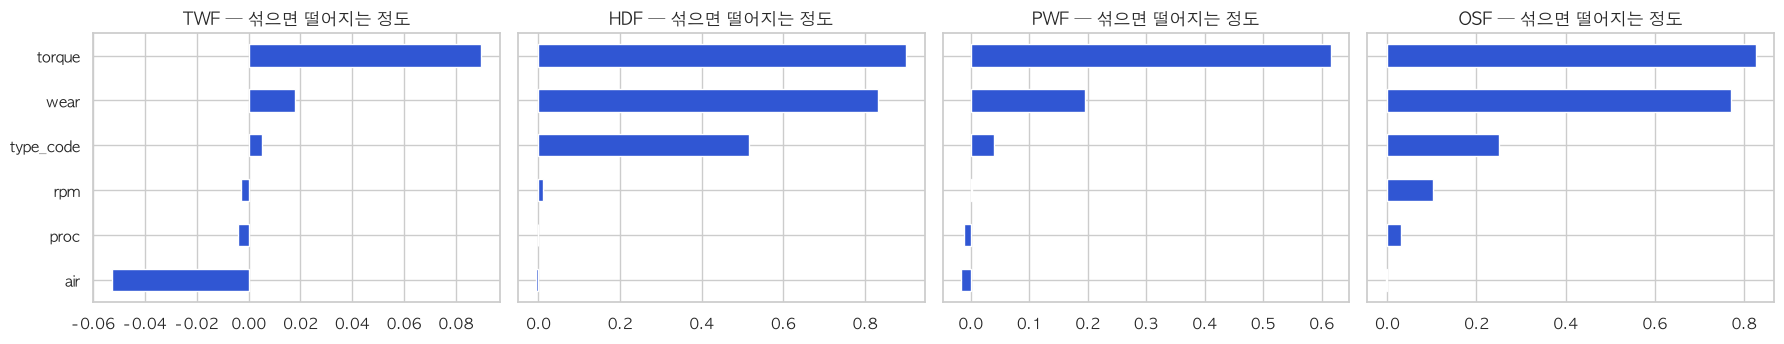

,TWF,HDF,PWF,OSF
type_code,-0.003,0.012,0.040,0.252
air,-0.004,0.901,0.001,-0.004
proc,-0.053,0.517,-0.012,0.031
rpm,0.018,0.833,0.195,0.103
torque,0.005,-0.005,0.616,0.826
wear,0.090,-0.001,-0.016,0.770


In [10]:
imp = {}
for cls in FAILS:
    d = train[train["label"].isin([cls, "NONE"])]
    y = (d["label"] == cls).astype(int)
    Xa, Xb, ya, yb = train_test_split(d[BASE], y, test_size=0.3, stratify=y, random_state=SEED)
    m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced",
                                       categorical_features=[0], random_state=SEED).fit(Xa, ya)
    r = permutation_importance(m, Xb, yb, scoring="average_precision", n_repeats=20, random_state=SEED)
    imp[cls] = pd.Series(r.importances_mean, index=BASE)

imp = pd.DataFrame(imp)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, cls in zip(axes, FAILS):
    imp[cls].sort_values().plot.barh(ax=ax, color="#3056d3"); ax.set_title(f"{cls} — 섞으면 떨어지는 정도")
plt.tight_layout(); plt.show()
imp.round(3)

**읽을 점:** 클래스마다 점수를 크게 떨어뜨리는 변수 둘 정도가 그 고장을 정하는 변수 후보입니다. 3단계에서 그 두 변수를 함께 그려 경계 모양을 봅니다.

## 3. 그림으로 경계 모양 보기 — 클래스별 상위 변수 두 개

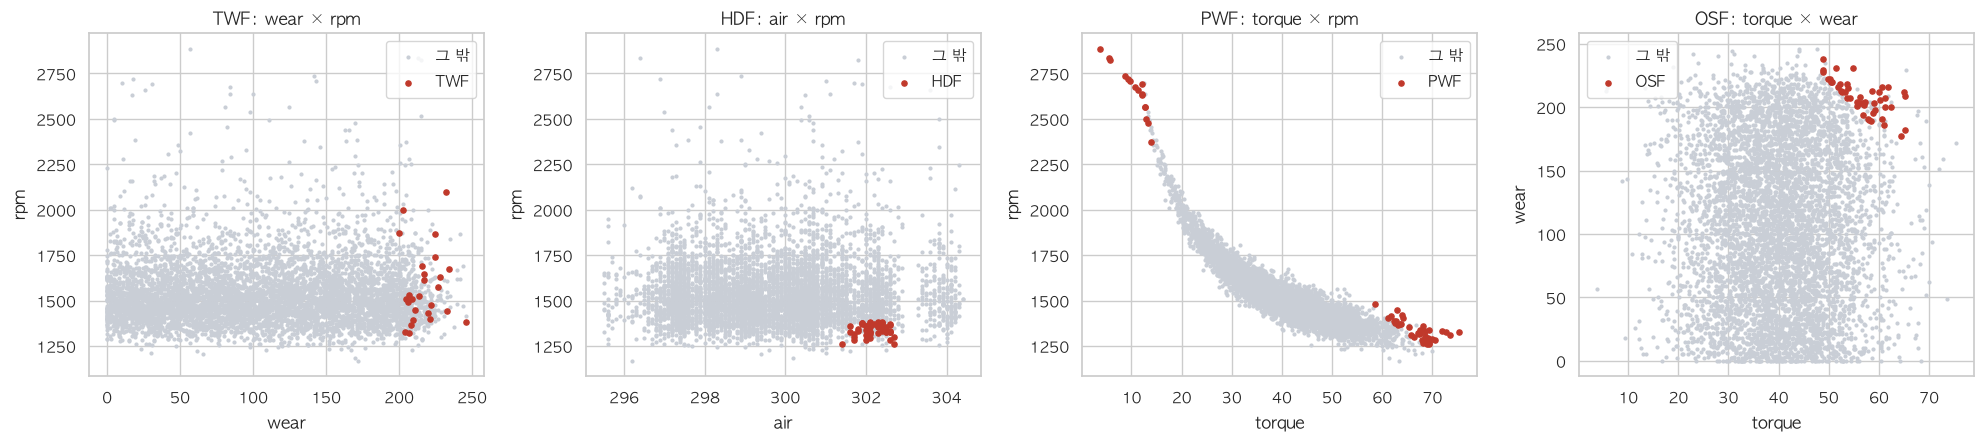

{'TWF': ('wear', 'rpm'),
 'HDF': ('air', 'rpm'),
 'PWF': ('torque', 'rpm'),
 'OSF': ('torque', 'wear')}

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
top2 = {}
for ax, cls in zip(axes, FAILS):
    a, b = imp[cls].drop("type_code").sort_values(ascending=False).index[:2]
    top2[cls] = (a, b)
    d = train.sample(frac=1, random_state=SEED)
    ax.scatter(d.loc[d.label != cls, a], d.loc[d.label != cls, b], s=4, c="#c9ced6", label="그 밖")
    ax.scatter(d.loc[d.label == cls, a], d.loc[d.label == cls, b], s=14, c="#c0392b", label=cls)
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"{cls}: {a} × {b}"); ax.legend()
plt.tight_layout(); plt.show()
top2

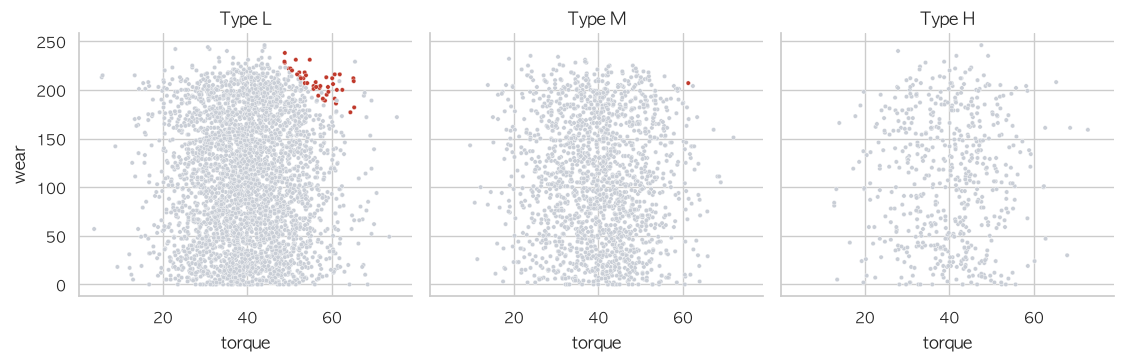

In [12]:
# OSF는 Type(L · M · H)마다 경계가 다른지 따로 그려 봄
a, b = top2["OSF"]
train["is_osf"] = train["label"] == "OSF"
g = sns.FacetGrid(train, col="Type", col_order=["L", "M", "H"], height=3.8)
g.map_dataframe(sns.scatterplot, x=a, y=b, hue="is_osf", palette={False: "#c9ced6", True: "#c0392b"}, s=10)
g.set_titles("Type {col_name}"); plt.show()

**읽을 점:** 경계가 직선이 아니라 **곡선(쌍곡선 모양)**이면 두 변수의 **곱**이 일정한 선일 가능성이 있습니다. 경계가 축에 나란한 띠면 한 변수의 **구간**입니다. Type마다 경계 높이가 다르면 Type별 기준이 있다는 뜻입니다. 4 · 5단계에서 숫자로 확인합니다.

## 3-1. 분포 이동 확인 — train과 val에서 값이 흘러가는 변수

KS 통계량(train ↔ val, 클수록 분포가 다름): {'air': 0.123, 'proc': 0.092, 'rpm': 0.015, 'torque': 0.017, 'wear': 0.013} → 흘러가는 변수: ['air', 'proc']


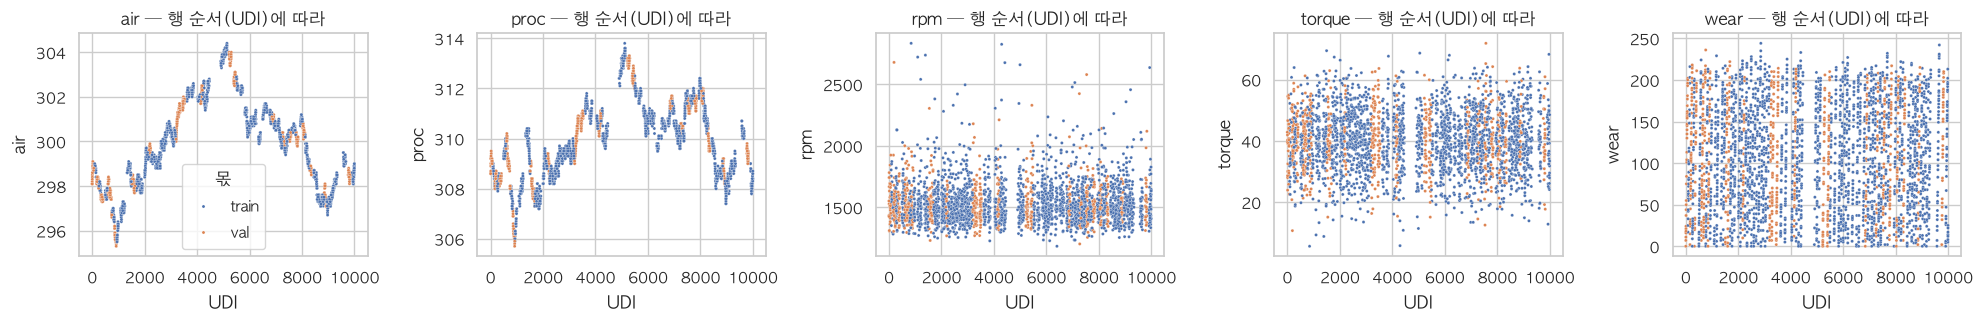

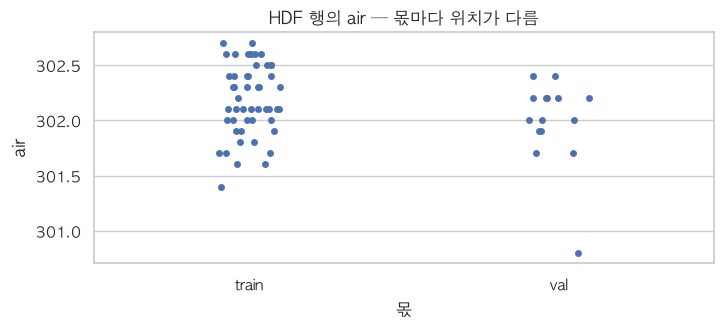

In [13]:
from scipy.stats import ks_2samp
drift = pd.Series({f: ks_2samp(train[f], val[f]).statistic for f in NUM}).round(3)
DRIFT = drift[drift > 0.05].index.tolist()
print("KS 통계량(train ↔ val, 클수록 분포가 다름):", drift.to_dict(), "→ 흘러가는 변수:", DRIFT)

both = pd.concat([train.assign(몫="train"), val.assign(몫="val")])
fig, axes = plt.subplots(1, len(NUM), figsize=(20, 3.4))
for ax, f in zip(axes, NUM):
    sns.scatterplot(data=both.sample(3000, random_state=SEED), x="UDI", y=f, hue="몫", s=5, ax=ax, legend=(f == NUM[0]))
    ax.set_title(f"{f} — 행 순서(UDI)에 따라")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 3))
sns.stripplot(data=both[both["label"] == "HDF"], x="몫", y="air", ax=ax)
ax.set_title("HDF 행의 air — 몫마다 위치가 다름"); plt.show()

**읽을 점:** 행 순서에 따라 천천히 흘러가는 변수(예: 온도 절댓값)는 몫마다 범위가 달라, 그 **절댓값**으로 배운 기준이 다른 몫에서 맞지 않습니다. 이런 변수는 **두 변수의 차 · 비 같은 상대값**으로 바꾸고 원래 칸은 빼는 것을 7단계에서 시험합니다.

## 4. 변수 조합 자동 탐색 — 곱 · 비 · 차 · 합 중 무엇이 가장 잘 가르나

,클래스,원래 변수 최고,조합 최고,조합 점수,나아짐
0,TWF,0.125,air+wear,0.151,0.026
1,HDF,0.061,air/proc,0.150,0.089
2,PWF,0.526,rpm×torque,0.642,0.116
3,OSF,0.090,torque×wear,0.541,0.451


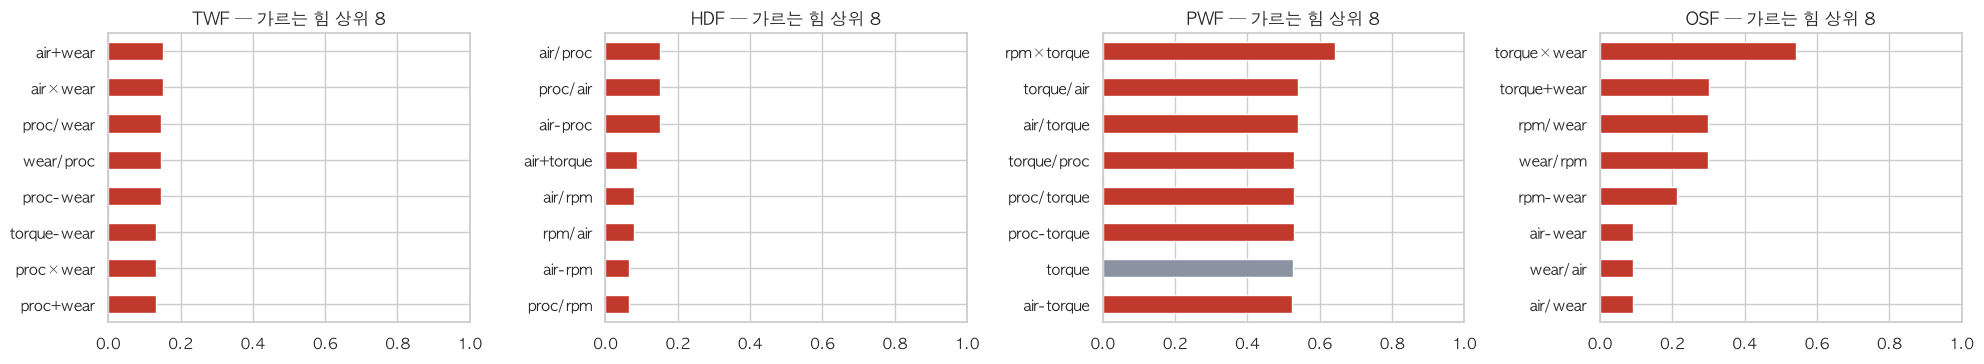

In [14]:
def sep_score(x, y):
    # 한 변수만으로 클래스를 얼마나 잘 가르는지(average precision, 큰 쪽 · 작은 쪽 중 나은 값)
    x = np.nan_to_num(np.asarray(x, dtype=float), nan=0.0, posinf=1e12, neginf=-1e12)   # 0으로 나눈 값 처리
    return max(average_precision_score(y, x), average_precision_score(y, -x))


def candidates(df):
    out = {f: df[f] for f in NUM}
    for a, b in combinations(NUM, 2):
        out[f"{a}×{b}"] = df[a] * df[b]
        out[f"{a}/{b}"] = df[a] / df[b]
        out[f"{b}/{a}"] = df[b] / df[a]
        out[f"{a}-{b}"] = df[a] - df[b]
        out[f"{a}+{b}"] = df[a] + df[b]
    return pd.DataFrame(out)


C = candidates(train)
rank = {}
for cls in FAILS:
    y = (train["label"] == cls).astype(int)
    rank[cls] = C.apply(lambda col: sep_score(col.values, y.values)).sort_values(ascending=False)

summary = []
for cls in FAILS:
    best_raw = rank[cls][NUM].max()
    best_name, best_val = rank[cls].index[0], rank[cls].iloc[0]
    summary.append({"클래스": cls, "원래 변수 최고": round(best_raw, 3), "조합 최고": best_name, "조합 점수": round(best_val, 3),
                    "나아짐": round(best_val - best_raw, 3)})
summary = pd.DataFrame(summary)
display(summary)

fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, cls in zip(axes, FAILS):
    rank[cls].head(8)[::-1].plot.barh(ax=ax, color=["#c0392b" if "×" in i or "/" in i or "-" in i or "+" in i else "#8b93a3" for i in rank[cls].head(8)[::-1].index])
    ax.set_title(f"{cls} — 가르는 힘 상위 8"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

**읽을 점:** 원래 변수보다 **크게 나아진 조합**(빨강)이 그 고장을 정하는 숨은 변수 후보입니다. 아래 칸이 기준(나아짐 0.1 넘음, 또는 원래보다 2배 넘고 0.05 넘음)에 맞는 조합만 파생 변수로 고릅니다(사람이 고르지 않음).

In [15]:
picked = {r["클래스"]: r["조합 최고"] for _, r in summary.iterrows()
          if r["나아짐"] > 0.10 or (r["조합 점수"] >= 2 * r["원래 변수 최고"] and r["나아짐"] > 0.05)}
print("파생 변수로 고른 조합:", picked)


def make_feature(df, name):
    for op in ["×", "/", "-", "+"]:
        if op in name:
            a, b = name.split(op)
            v = {"×": df[a] * df[b], "/": df[a] / df[b], "-": df[a] - df[b], "+": df[a] + df[b]}[op]
            return v.replace([np.inf, -np.inf], np.nan).fillna(0)
    return df[name]

파생 변수로 고른 조합: {'HDF': 'air/proc', 'PWF': 'rpm×torque', 'OSF': 'torque×wear'}


In [16]:
# 고른 조합이 Type마다 다른 기준을 갖는지 — Type별 얕은 트리(깊이 1)로 기준값 찾기
type_thr = {}
for cls, name in picked.items():
    thr = {}
    for t in ["L", "M", "H"]:
        d = train[train["Type"] == t]
        y = (d["label"] == cls).astype(int)
        if y.sum() < 3:
            continue
        stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(make_feature(d, name).to_frame(), y)
        thr[t] = float(stump.tree_.threshold[0])
    type_thr[cls] = thr
pd.DataFrame(type_thr).round(1)

,HDF,PWF,OSF
L,1.0,85955.4,11006.5
M,1.0,85936.2,NaN
H,1.0,85998.0,NaN


**읽을 점:** 같은 조합인데 Type마다 기준값이 뚜렷이 다르면, 조합 값을 **Type별 기준으로 나눈 비율**이 Type과 상관없이 하나의 기준(≈ 1)으로 가르는 변수가 됩니다. 기준값은 train에서 찾은 값입니다.

## 5. 구간 찾기 — 조합으로도 안 갈리는 클래스(TWF 등)

조합으로 안 갈린 클래스: ['TWF']

[TWF] wear 얕은 트리
|--- wear <= 202.50
|   |--- wear <= 199.50
|   |   |--- class: 0
|   |--- wear >  199.50
|   |   |--- class: 0
|--- wear >  202.50
|   |--- wear <= 224.50
|   |   |--- class: 0
|   |--- wear >  224.50
|   |   |--- class: 0

→ TWF가 몰린 구간: wear 224 ~ 247 (그 구간 46행 중 TWF 비율 17.4%)


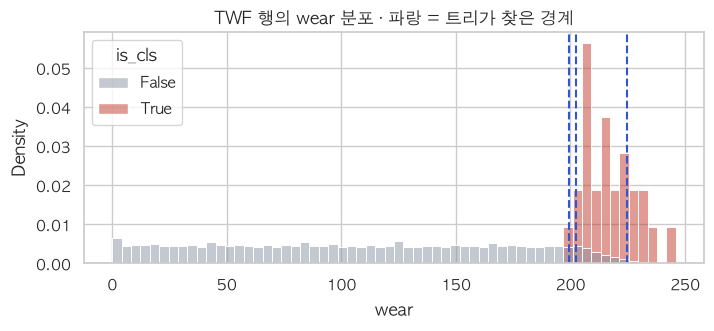

In [17]:
left = [c for c in FAILS if c not in picked]
print("조합으로 안 갈린 클래스:", left)
bands = {}
for cls in left:
    f = imp[cls].drop(["type_code"] + DRIFT).idxmax()       # 2단계 1등 변수(흘러가는 변수는 뺌 — 3-1단계)
    y = (train["label"] == cls).astype(int)
    tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=30, random_state=SEED).fit(train[[f]], y)
    print(f"\n[{cls}] {f} 얕은 트리\n" + export_text(tree, feature_names=[f]))
    cuts = sorted(t for t in tree.tree_.threshold if t > -2)
    edges = [train[f].min() - 1] + cuts + [train[f].max() + 1]
    rates = [(lo, hi, y[(train[f] > lo) & (train[f] <= hi)].mean(), int(((train[f] > lo) & (train[f] <= hi)).sum()))
             for lo, hi in zip(edges[:-1], edges[1:])]
    rates = [r for r in rates if r[3] > 0]
    lo, hi, rate, n = max(rates, key=lambda r: r[2])
    bands[cls] = (f, lo, hi)
    print(f"→ {cls}가 몰린 구간: {f} {lo:.0f} ~ {hi:.0f} (그 구간 {n}행 중 {cls} 비율 {rate:.1%})")

    fig, ax = plt.subplots(figsize=(8, 3))
    train["is_cls"] = train["label"] == cls
    sns.histplot(data=train, x=f, hue="is_cls", bins=60, stat="density", common_norm=False, ax=ax,
                 palette={False: "#8b93a3", True: "#c0392b"})
    for c in cuts: ax.axvline(c, color="#3056d3", ls="--")
    ax.set_title(f"{cls} 행의 {f} 분포 · 파랑 = 트리가 찾은 경계"); plt.show()

**읽을 점:** 고장이 특정 구간에만 몰리면 **구간 표시 변수**가 도움이 됩니다. 다만 그 구간 안에서 고장 비율이 낮으면(몇 %) 그 안에서 누가 고장 날지는 이 데이터로 가를 수 없다는 뜻입니다 — 점수 한계로 받아들입니다.

## 6. 정답 잡음 확인 (train)

In [18]:
noise = pd.DataFrame({
    "고장=1인데 유형 없음": [int(((train["Machine failure"] == 1) & (train[FAILS + ["RNF"]].sum(axis=1) == 0)).sum())],
    "유형이 둘 이상": [int((train[FAILS].sum(axis=1) > 1).sum())],
    "RNF(무작위 고장)": [int(train["RNF"].sum())],
    "RNF인데 고장=0": [int(((train["RNF"] == 1) & (train["Machine failure"] == 0)).sum())],
}, index=["행 수"])
noise

,고장=1인데 유형 없음,유형이 둘 이상,RNF(무작위 고장),RNF인데 고장=0
행 수,7,14,11,11


**읽을 점:** 원인을 알 수 없는 행(유형 없는 고장)과 유형이 겹치는 행은 경계를 흐리게 합니다. 7단계에서 **학습 데이터에서만** 빼 보고 val로 효과를 확인합니다(val · test는 그대로).

## 7. 정제안 비교 — val로 고르기

In [19]:
def refine(df):
    out = df.copy()
    for cls, name in picked.items():
        col = f"f_{name}"
        out[col] = make_feature(out, name)
        thr = type_thr.get(cls, {})
        if len(thr) == 3 and (max(thr.values()) - min(thr.values())) / np.mean(list(thr.values())) > 0.05:
            out[f"{col}_ratio"] = out[col] / out["Type"].map(thr)       # Type별 기준으로 나눈 비율
    for cls, (f, lo, hi) in bands.items():
        out[f"zone_{f}"] = ((out[f] > lo) & (out[f] <= hi)).astype(int)
    return out


tr2, va2, te2 = refine(train), refine(val), refine(test)
NEW = [c for c in tr2.columns if c.startswith(("f_", "zone_"))]
clean = tr2[~(((tr2["Machine failure"] == 1) & (tr2[FAILS + ["RNF"]].sum(axis=1) == 0)) | (tr2[FAILS].sum(axis=1) > 1))]
print("새 칸:", NEW, "| 정제 뒤 train 행:", len(clean), "/", len(tr2))

variants = {
    "A 기준(원래 칸)": (tr2, BASE),
    "B + 파생 변수": (tr2, BASE + NEW),
    "C + 파생 변수 + 잡음 행 뺌": (clean, BASE + NEW),
}
# D: 흘러가는 원래 칸(3-1단계)을 빼고 상대값(파생 변수)만 남김 — 변수 제거
variants["D + 흘러가는 원래 칸 뺌"] = (clean, [f for f in BASE + NEW if f not in DRIFT])
print("D에서 뺀 칸:", DRIFT)

scores = {}
for name, (tr, feats) in variants.items():
    _, f1 = fit_eval(tr, va2, feats, show=False)
    scores[name] = f1
scores = pd.DataFrame(scores).T.round(3)
best_variant = scores["macro"].idxmax()
print("val로 고른 안:", best_variant)
scores

새 칸: ['f_air/proc', 'f_rpm×torque', 'f_torque×wear', 'zone_wear'] | 정제 뒤 train 행: 5714 / 5735
D에서 뺀 칸: ['air', 'proc']
val로 고른 안: B + 파생 변수


,NONE,TWF,HDF,PWF,OSF,macro
A 기준(원래 칸),0.991,0.125,0.786,0.765,0.824,0.698
B + 파생 변수,0.995,0.133,0.933,0.923,0.938,0.784
C + 파생 변수 + 잡음 행 뺌,0.995,0.133,0.933,0.919,0.909,0.778
D + 흘러가는 원래 칸 뺌,0.996,0.000,0.933,0.923,0.970,0.764


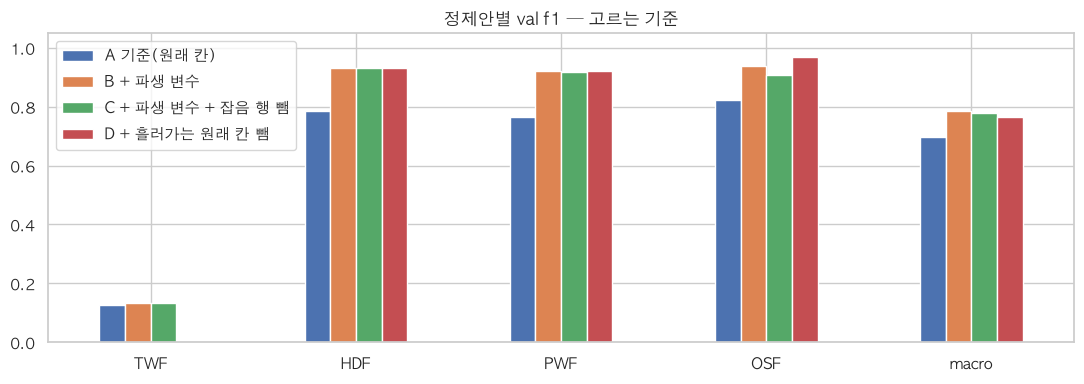

In [20]:
ax = scores[FAILS + ["macro"]].T.plot.bar(figsize=(11, 4), rot=0)
ax.set_title("정제안별 val f1 — 고르는 기준"); ax.set_ylim(0, 1.05); plt.tight_layout(); plt.show()

## 8. 전후 비교 — test는 여기서 한 번만

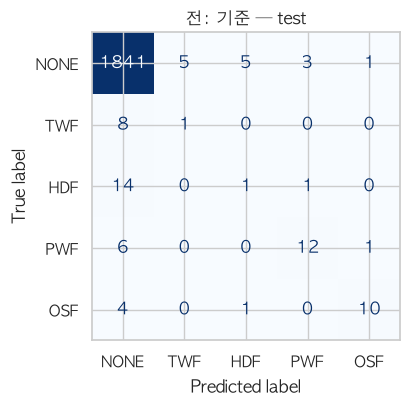

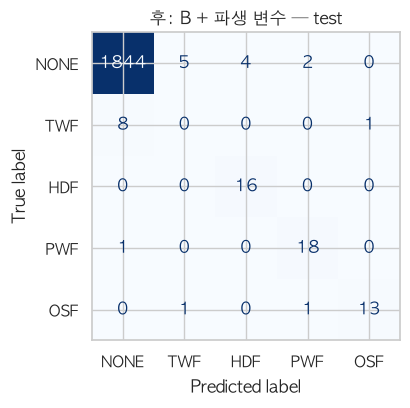

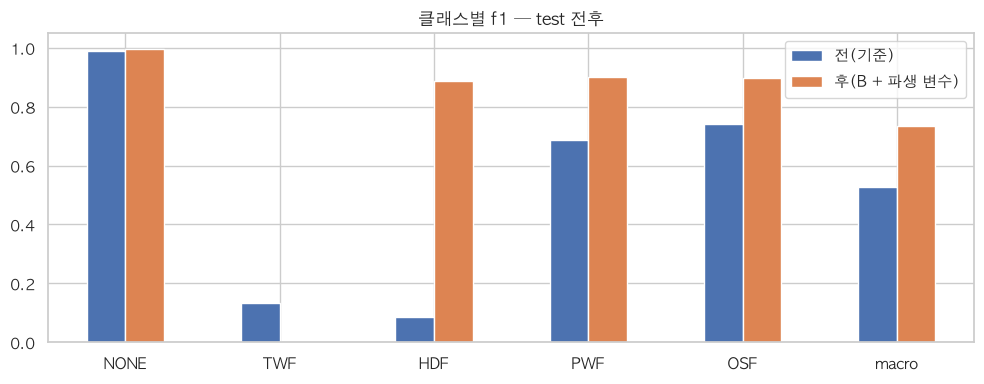

,전(기준),후(B + 파생 변수),차이
NONE,0.988,0.995,0.007
TWF,0.133,0.000,-0.133
HDF,0.087,0.889,0.802
PWF,0.686,0.900,0.214
OSF,0.741,0.897,0.156
macro,0.527,0.736,0.209


In [21]:
tr_b, feats_b = variants[best_variant]
_, before = fit_eval(tr2, te2, BASE, "전: 기준 — test")
_, after = fit_eval(tr_b, te2, feats_b, f"후: {best_variant} — test")
cmp = pd.DataFrame({"전(기준)": before, f"후({best_variant})": after}).round(3)
cmp["차이"] = (cmp.iloc[:, 1] - cmp.iloc[:, 0]).round(3)
ax = cmp.iloc[:, :2].plot.bar(figsize=(10, 4), rot=0); ax.set_ylim(0, 1.05); ax.set_title("클래스별 f1 — test 전후")
plt.tight_layout(); plt.show()
cmp

## 9. (선택) AutoGluon으로 다시 확인

앞 노트북(`autogluon_compare.ipynb`)과 같은 설정으로, 고른 정제안 칸만 넣어 다시 학습합니다. 시간이 걸립니다.

In [22]:
RUN_AUTOGLUON = 1
if RUN_AUTOGLUON:
    from autogluon.tabular import TabularPredictor
    cols = feats_b + ["label"]
    p = TabularPredictor(label="label", eval_metric="f1_macro", sample_weight="balance_weight", path="ag-ai4i-refined").fit(
        tr_b[cols], tuning_data=va2[cols], presets="medium_quality", time_limit=600)
    lb = p.leaderboard(te2[cols], extra_metrics=["balanced_accuracy"], silent=True).sort_values("score_val", ascending=False)
    display(lb[["model", "score_val", "score_test", "balanced_accuracy"]])

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.15
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 24.6.0: Mon Jul 14 11:30:30 PDT 2025; root:xnu-11417.140.69~1/RELEASE_ARM64_T6020
CPU Count:          12
Pytorch Version:    2.10.0
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       6.56 GB / 32.00 GB (20.5%)
Disk Space Avail:   168.14 GB / 926.35 GB (18.2%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Using predefined sample weighting strategy: balance_weight. Evaluation metrics will ignore sample weights, specify weight_evaluation=True to instead report weighted metrics.
Beginning AutoGluon training ... Time limit = 600s
AutoGluon will save models to "/Users/insujo/Documents/repo/orchestration/data/ai4i

[1000]	valid_set's multi_logloss: 0.101611	valid_set's f1_macro: 0.693223


	0.7004	 = Validation score   (f1_macro)
	26.3s	 = Training   runtime
	0.06s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 570.30s of the 570.30s of remaining time.
	Fitting with cpus=12, gpus=0, mem=0.1/6.5 GB
	0.7895	 = Validation score   (f1_macro)
	8.94s	 = Training   runtime
	0.01s	 = Validation runtime
Fitting model: RandomForestGini ... Training model for up to 561.33s of the 561.33s of remaining time.
	Fitting with cpus=12, gpus=0, mem=0.1/6.5 GB
	0.7702	 = Validation score   (f1_macro)
	0.41s	 = Training   runtime
	0.04s	 = Validation runtime
Fitting model: RandomForestEntr ... Training model for up to 560.87s of the 560.86s of remaining time.
	Fitting with cpus=12, gpus=0, mem=0.1/6.4 GB
	0.7702	 = Validation score   (f1_macro)
	0.41s	 = Training   runtime
	0.04s	 = Validation runtime
Fitting model: CatBoost ... Training model for up to 560.41s of the 560.41s of remaining time.
	Fitting with cpus=12, gpus=0
	0.7561	 = Validation score   (f1_macro)

,model,score_val,score_test,balanced_accuracy
0,LightGBMLarge,0.812350,0.772872,0.794677
1,WeightedEnsemble_L2,0.812350,0.772872,0.794677
3,XGBoost,0.805669,0.761214,0.793275
2,LightGBM,0.789535,0.769826,0.773425
4,RandomForestGini,0.770203,0.760631,0.760601
5,RandomForestEntr,0.770203,0.754686,0.773611
6,CatBoost,0.756115,0.710259,0.726696
8,NeuralNetFastAI,0.726091,0.616571,0.548692
10,NeuralNetTorch,0.719252,0.576304,0.516064
9,ExtraTreesGini,0.713464,0.586729,0.555872


## 정리할 것
- 고른 파생 변수 · 기준값 · 구간은 **train에서 찾은 값**입니다. 이 칸들을 쓰면 C1-a15 에이전트도 같은 값을 계산해야 하므로, 1단계 ONNX 입력 약속에 넣습니다.
- TWF처럼 구간 안에서 고장 비율이 낮은 클래스는 데이터 한계입니다. 시연에서는 '고장 확정'보다 '위험 구간'으로 보여 주는 편이 맞습니다.